In [74]:
# Setup Python

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

OUTPUT_DIR = Path('output')
FIG_DIR = OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [63]:
# Dataset Loading & Integration Datset

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
train['source'] = 'train'
test['source'] = 'test'

raw = pd.concat([train, test], ignore_index=True)
print('Number of rows:', f'{raw.shape[0]:,}', '| Number of columns:', raw.shape[1])
raw.head()

Number of rows: 129,880 | Number of columns: 26


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,source
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied,train
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied,train
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied,train
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied,train
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied,train


In [64]:
# Cleaning Data

data = raw.copy()

data.columns = (
    data.columns.str.strip()
    .str.lower()
    .str.replace(r'[^a-z0-9]+', '_', regex=True)
    .str.strip('_')
)

unnamed_cols = [c for c in data.columns if c.startswith('unnamed')]
if unnamed_cols:
    data = data.drop(columns=unnamed_cols)

log = []

def add_log(step, before, after, note=''):
    log.append({
        'langkah': step,
        'baris_sebelum': before,
        'baris_sesudah': after,
        'catatan': note,
    })


ringkasan = pd.DataFrame({
    'kolom': data.columns,
    'dtype': data.dtypes.astype(str).values,
    'missing': data.isna().sum().values,
    'pct_missing': (data.isna().mean().values * 100).round(2),
})

print(f'Data summary -> rows: {len(data):,} | columns: {data.shape[1]}')
print(ringkasan[ringkasan['missing'] > 0].to_string(index=False))

Data summary -> rows: 129,880 | columns: 25
                   kolom   dtype  missing  pct_missing
arrival_delay_in_minutes float64      393          0.3


In [65]:
# Duplikat

n = len(data)
id_col = 'id' if 'id' in data.columns else None
n_dup = data.duplicated(subset = [id_col]).sum() if id_col else data.dupliated().sum()
data = data.drop_duplicates(subset = [id_col]) if id_col else data.drop_duplicates()
add_log('Discard duplicates', n, len(data), f'{n_dup} baris duplikat')

print('Duplicates removed:', n_dup)

Duplicates removed: 0


In [66]:
# Missing Value

dep, arr = 'departure_delay_in_minutes', 'arrival_delay_in_minutes'

corr_val = data[dep].corr(data[arr])
missing_cnt = data[arr].isna().sum()
missing_pct = data[arr].isna().mean()
data = data.dropna(subset=[arr])

print(f'Correlation {dep} vs {arr}: {corr_val:.4f}')
print(f'Missing {arr}: {missing_cnt:,} ({missing_pct:.2%})')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print('Correlation of departure vs arrival delays:')
print(data[[dep, arr]].corr().round(4))

Correlation departure_delay_in_minutes vs arrival_delay_in_minutes: 0.9653
Missing arrival_delay_in_minutes: 393 (0.30%)
Correlation of departure vs arrival delays:
                            departure_delay_in_minutes  arrival_delay_in_minutes
departure_delay_in_minutes                      1.0000                    0.9653
arrival_delay_in_minutes                        0.9653                    1.0000


In [67]:
# Verification

rating_cols = [
    c
    for c in data.columns
    if pd.api.types.is_numeric_dtype(data[c])
    and data[c].max() <= 5
    and data[c].min() >= 0
]
zero_count = (data[rating_cols] == 0).sum()
zero_pct = ((data[rating_cols] == 0).mean() * 100).round(2)

tabel_zero = (
    pd.DataFrame({
        'Attribute': rating_cols,
        'Amount': zero_count.values,
        'percent': zero_pct.map(lambda x: f'{x:.2f}%').values,
    })
    .sort_values('Amount', ascending=False)
    .reset_index(drop=True)
)

print(f'Total rating attributes ({len(rating_cols)}):')
for col in rating_cols:
    print(f'  - {col}')

print('\nProportion of 0 scores in rating data:')
print(tabel_zero.to_string(index=False))

n_zero = int(zero_count.sum())
data[rating_cols] = data[rating_cols].replace(0, np.nan)
add_log(
    'Score 0 changed to blank',
    len(data),
    len(data),
    f'{n_zero:,} cell; assumption: 0 = not applicable',
)

Total rating attributes (14):
  - inflight_wifi_service
  - departure_arrival_time_convenient
  - ease_of_online_booking
  - gate_location
  - food_and_drink
  - online_boarding
  - seat_comfort
  - inflight_entertainment
  - on_board_service
  - leg_room_service
  - baggage_handling
  - checkin_service
  - inflight_service
  - cleanliness

Proportion of 0 scores in rating data:
                        Attribute  Amount percent
departure_arrival_time_convenient    6664   5.15%
           ease_of_online_booking    5666   4.38%
            inflight_wifi_service    3908   3.02%
                  online_boarding    3071   2.37%
                 leg_room_service     596   0.46%
                   food_and_drink     130   0.10%
           inflight_entertainment      18   0.01%
                      cleanliness      14   0.01%
                 on_board_service       5   0.00%
                 inflight_service       5   0.00%
                    gate_location       1   0.00%
                  

In [68]:
# Quality Log

data['satisfied'] = (data['satisfaction'] == 'satisfied').astype(int)
data['age_group'] = pd.cut(
    data['age'],
    bins = [0, 24, 34, 44, 54, 64, 120],
    labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+'],
)

quality_log = pd.DataFrame(log)

styled_log = (
    quality_log.rename(
        columns = {
            'langkah': 'Langkah',
            'baris_sebelum': 'Baris Sebelum',
            'baris_sesudah': 'Baris Sesudah',
            'catatan': 'Catatan',
        }
    )
    .style.hide(axis='index')
    .format({'Baris Sebelum': '{:,}', 'Baris Sesudah': '{:,}'})
    .set_properties(subset=['Catatan'], **{'text-align': 'left'})
)

display(styled_log)
print(f'Final summary -> Clean Data: {len(data):,} rows | Columns: {data.shape[1]}')

Langkah,Baris Sebelum,Baris Sesudah,Catatan
Discard duplicates,"129,880","129,880",0 baris duplikat
Score 0 changed to blank,"129,487","129,487","20,080 cell; assumption: 0 = not applicable"


Final summary -> Clean Data: 129,487 rows | Columns: 27


=== Distribusi gender ===
        jumlah  persen (%)
gender                    
Female   65703       50.74
Male     63784       49.26

=== Distribusi customer_type ===
                   jumlah  persen (%)
customer_type                        
Loyal Customer     105773       81.69
disloyal Customer   23714       18.31

=== Distribusi type_of_travel ===
                 jumlah  persen (%)
type_of_travel                     
Business travel   89445       69.08
Personal Travel   40042       30.92

=== Distribusi class ===
          jumlah  persen (%)
class                       
Business   61990       47.87
Eco        58117       44.88
Eco Plus    9380        7.24

=== Distribusi age_group ===
           jumlah  persen (%)
age_group                    
35-44       30007       23.17
45-54       26757       20.66
25-34       24597       19.00
<25         24588       18.99
55-64       17572       13.57
65+          5966        4.61



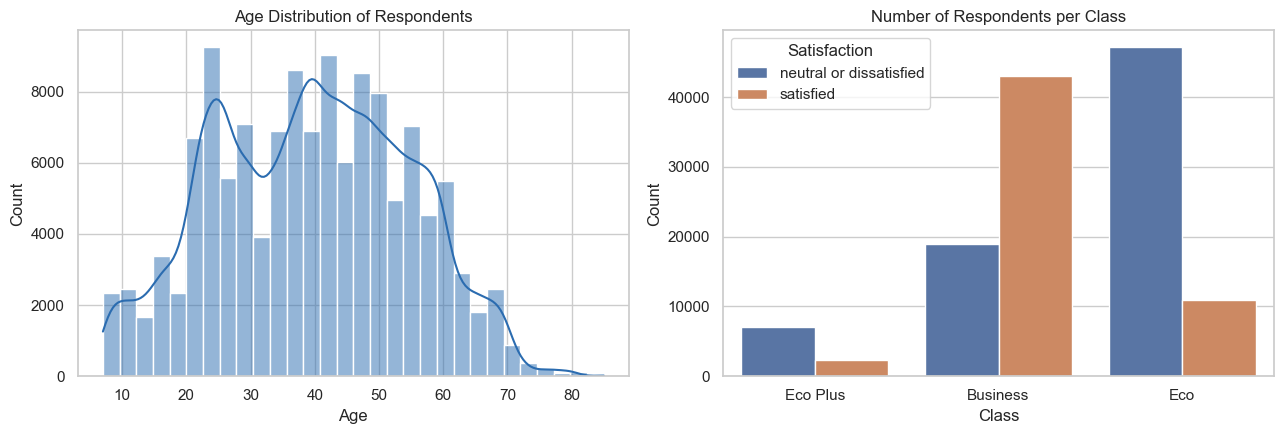

In [73]:
# Respondent Profile

profil_cols = ['gender', 'customer_type', 'type_of_travel', 'class', 'age_group']

for col in profil_cols:
  dist = pd.DataFrame({
      'jumlah': data[col].value_counts(dropna=False),
      'persen (%)': (
          data[col].value_counts(normalize=True, dropna=False) * 100
      ).round(2),
  })
  print(f'=== Distribusi {col} ===')
  print(dist.to_string())
  print()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data['age'], bins=30, kde=True, ax=axes[0], color='#2b6cb0')
axes[0].set_title('Age Distribution of Respondents')
axes[0].set_xlabel('Age')

sns.countplot(data=data, x='class', hue='satisfaction', ax=axes[1])
axes[1].set_title('Number of Respondents per Class')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
axes[1].legend(title='Satisfaction')

plt.tight_layout()
plt.savefig(FIG_DIR / '01_profil_responden.png', dpi=200)
plt.show()

In [77]:
# Executive Matrics

def wilson_ci(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

k, n = int(data['satisfied'].sum()), len(data)
lo, hi = wilson_ci(k, n)
print(
    f'Percent satisfied: {k/n:.2%} | CI 95% Wilson: {lo:.2%} - {hi:.2%} | n ='
    f' {n:,}'
)

Percent satisfied: 43.45% | CI 95% Wilson: 43.18% - 43.72% | n = 129,487


In [85]:
# Crosstab per segment and significance test

def cramers_v(ct):
  chi2 = stats.chi2_contingency(ct)[0]
  n = ct.values.sum()
  r, c = ct.shape
  denom = n * (min(r, c) - 1)
  return np.sqrt(chi2 / denom) if denom > 0 else np.nan


segments = ['customer_type', 'type_of_travel', 'class', 'gender', 'age_group']
rows = []

for seg in segments:
  ct = pd.crosstab(data[seg], data['satisfied'])
  chi2, p, dof, _ = stats.chi2_contingency(ct)
  v = cramers_v(ct)

  rows.append({
      'segmen': seg,
      'chi2': round(chi2, 2),
      'dof': dof,
      'p_value': f'{p:.2e}' if p < 0.0001 else f'{p:.4f}',
      'cramers_v': round(v, 4),
  })

  pct_puas = (
      data.groupby(seg, observed=False)['satisfied']
      .mean()
      .mul(100)
      .round(1)
      .reset_index(name='% puas')
  )
  print(f'=== {seg} ===')
  print(pct_puas.to_string(index=False))
  print()

seg_tests = (
    pd.DataFrame(rows)
    .sort_values('cramers_v', ascending=False)
    .reset_index(drop=True)
)

styled_tests = (
    seg_tests.rename(
        columns={
            'segmen': 'Segmen',
            'chi2': 'Chi-Square',
            'dof': 'df',
            'p_value': 'p-value',
            'cramers_v': "Cramér's V",
        }
    )
    .style.hide(axis='index')
    .format({'Chi-Square': '{:,.2f}', "Cramér's V": '{:.4f}'})
)

display(styled_tests)

=== customer_type ===
    customer_type  % puas
   Loyal Customer    47.8
disloyal Customer    24.0

=== type_of_travel ===
 type_of_travel  % puas
Business travel    58.4
Personal Travel    10.1

=== class ===
   class  % puas
Business    69.4
     Eco    18.8
Eco Plus    24.6

=== gender ===
gender  % puas
Female    42.9
  Male    44.0

=== age_group ===
age_group  % puas
      <25    27.8
    25-34    37.0
    35-44    50.3
    45-54    58.0
    55-64    49.1
      65+    18.3



Segmen,Chi-Square,df,p-value,Cramér's V
class,"32,823.12",2,0.00e+00,0.5035
type_of_travel,"26,195.14",1,0.00e+00,0.4498
age_group,"7,512.33",5,0.00e+00,0.2409
customer_type,"4,475.16",1,0.00e+00,0.1859
gender,17.07,1,3.61e-05,0.0115


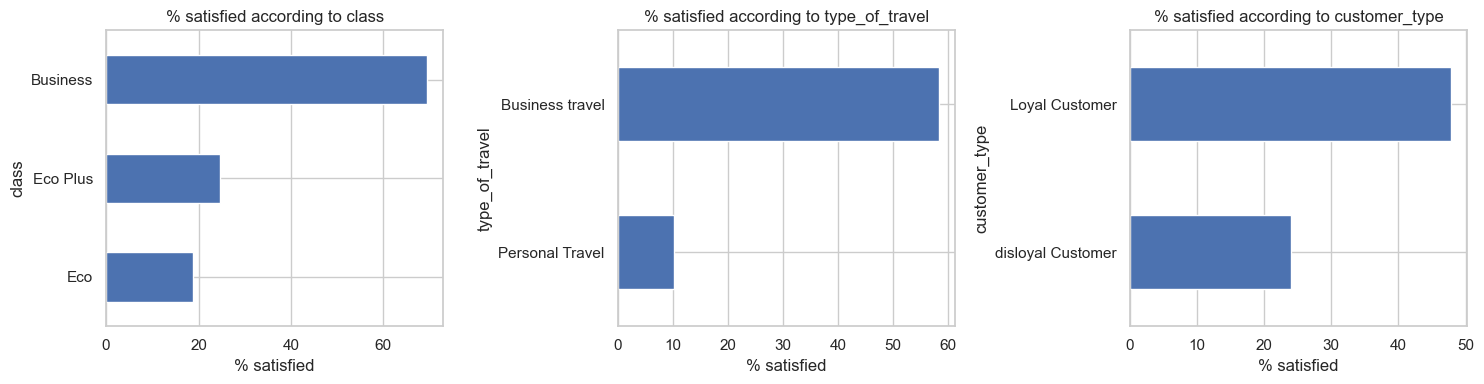

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, seg in zip(axes, ['class', 'type_of_travel', 'customer_type']):
    (data.groupby(seg)['satisfied'].mean() * 100).sort_values().plot.barh(ax=ax)
    ax.set_title('% satisfied according to ' + seg)
    ax.set_xlabel('% satisfied')
plt.tight_layout()
plt.savefig(FIG_DIR / '02_puas_per_segmen.png', dpi=200)
plt.show()

In [90]:
# Satisfaction driver analysis

importance = data[rating_cols].apply(lambda s: s.corr(data['satisfied']))
performance = data[rating_cols].mean()
ip = (pd.DataFrame({'importance': importance, 'performance': performance})
      .sort_values('importance', ascending=False))
display(ip.round(3))

,importance,performance
online_boarding,0.565,3.332
inflight_entertainment,0.398,3.359
inflight_wifi_service,0.390,2.813
seat_comfort,0.349,3.442
on_board_service,0.322,3.383
leg_room_service,0.316,3.367
cleanliness,0.307,3.287
baggage_handling,0.249,3.632
inflight_service,0.245,3.643
ease_of_online_booking,0.238,2.883


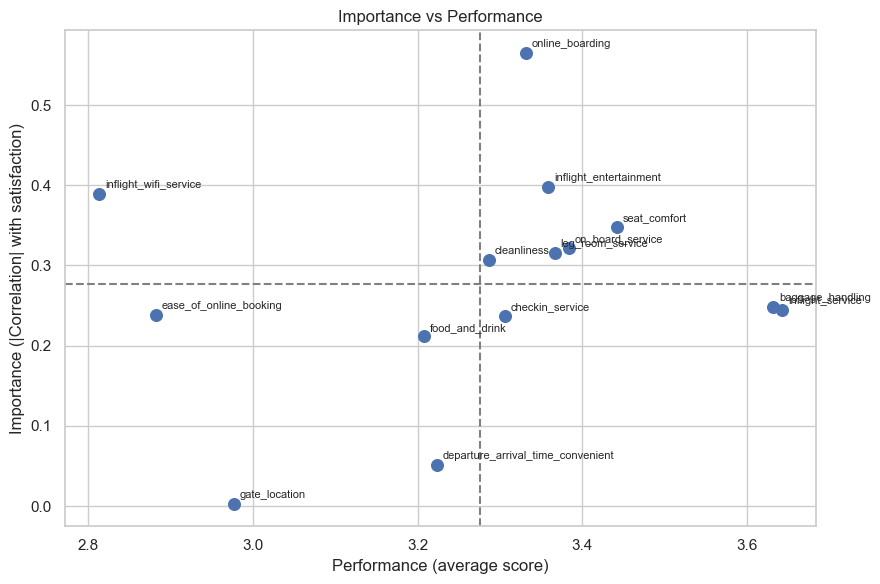

In [92]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(ip['performance'], ip['importance'].abs(), s=70)
for name, r in ip.iterrows():
    ax.annotate(name, (r['performance'], abs(r['importance'])),
                fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.axvline(ip['performance'].mean(), color='gray', linestyle='--')
ax.axhline(ip['importance'].abs().mean(), color='gray', linestyle='--')
ax.set_xlabel('Performance (average score)')
ax.set_ylabel('Importance (|Correlation| with satisfaction)')
ax.set_title('Importance vs Performance')
plt.tight_layout()
plt.savefig(FIG_DIR / '03_importance_vs_performance.png', dpi=200)
plt.show()

In [94]:
try:
    import statsmodels.api as sm
    cc = data[rating_cols + ['satisfied']].dropna()
    X = (cc[rating_cols] - cc[rating_cols].mean()) / cc[rating_cols].std()
    model = sm.Logit(cc['satisfied'], sm.add_constant(X)).fit(disp=0)
    odds = np.exp(model.params).rename('odds_ratio_per_1sd')
    display(pd.concat([odds, model.pvalues.rename('p_value')], axis=1)
            .sort_values('odds_ratio_per_1sd', ascending=False).round(3))
    print('Responden dengan data lengkap:', f'{len(cc):,}', 'dari', f'{len(data):,}')
except ImportError:
    print('statsmodels belum terpasang; lewati bagian ini atau gunakan scikit-learn.')

,odds_ratio_per_1sd,p_value
online_boarding,3.594,0.000
inflight_wifi_service,2.222,0.000
leg_room_service,1.673,0.000
inflight_entertainment,1.592,0.000
on_board_service,1.591,0.000
checkin_service,1.398,0.000
ease_of_online_booking,1.276,0.000
seat_comfort,1.259,0.000
cleanliness,1.102,0.000
baggage_handling,1.099,0.000


Responden dengan data lengkap: 119,204 dari 129,487


In [98]:
# Export Summary

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

quality_log.to_excel(
    OUTPUT_DIR / 'quality_log.xlsx', engine='openpyxl', index=False
)
seg_tests.to_excel(
    OUTPUT_DIR / 'segment_tests.xlsx', engine='openpyxl', index=False
)
ip.reset_index().rename(columns={'index': 'atribut'}).to_excel(
    OUTPUT_DIR / 'importance_performance.xlsx', engine='openpyxl', index=False
)
data.to_excel(
    OUTPUT_DIR / 'airline_clean.xlsx', engine='openpyxl', index=False
)

print(sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file()))

['.DS_Store', 'airline_clean.xlsx', 'importance_performance.xlsx', 'quality_log.xlsx', 'segment_tests.xlsx']
